<a href="https://colab.research.google.com/github/fahad11-mikey/MLA-0204/blob/main/Experiment-9%20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Linear Regression MSE: 27.673861377721373
Linear Regression R2: -0.11621044340597808
Polynomial Regression MSE: 0.619633045039498
Polynomial Regression R2: 0.9750074315068538


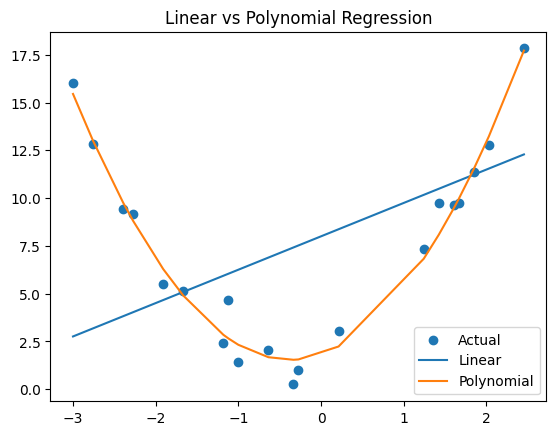

In [9]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

np.random.seed(42)
X = np.linspace(-3, 3, 100).reshape(-1, 1)
y = 2 + 1.5 * X.ravel() + 2 * X.ravel()**2 + np.random.normal(0, 1, 100)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

linear = LinearRegression()
linear.fit(X_train, y_train)
linear_pred = linear.predict(X_test)

poly = PolynomialFeatures(degree=2)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

polynomial = LinearRegression()
polynomial.fit(X_train_poly, y_train)
poly_pred = polynomial.predict(X_test_poly)

print("Linear Regression MSE:", mean_squared_error(y_test, linear_pred))
print("Linear Regression R2:", r2_score(y_test, linear_pred))
print("Polynomial Regression MSE:", mean_squared_error(y_test, poly_pred))
print("Polynomial Regression R2:", r2_score(y_test, poly_pred))

order = np.argsort(X_test[:, 0])
plt.scatter(X_test, y_test, label="Actual")
plt.plot(X_test[order], linear_pred[order], label="Linear")
plt.plot(X_test[order], poly_pred[order], label="Polynomial")
plt.legend()
plt.title("Linear vs Polynomial Regression")
plt.show()